<a href="https://colab.research.google.com/github/Abhishek2993/BrainCancer-Detection-MRI-DATA-/blob/main/Project_BCDCipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

:Brain cancer detection [RAW MRI SCANS]

In [ ]:
import kagglehub
import os
import tensorflow as tf

# Download the dataset
path = kagglehub.dataset_download("orvile/brain-cancer-mri-dataset")

# The correct path based on the dataset structure
DATASET_PATH = os.path.join(path, 'Brain_Cancer raw MRI data', 'Brain_Cancer')
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(f"Dataset downloaded to: {path}")
print(f"Training path: {DATASET_PATH}")

100%|██████████| 144M/144M [00:05<00:00, 25.4MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/orvile/brain-cancer-mri-dataset/versions/2
Training path: /root/.cache/kagglehub/datasets/orvile/brain-cancer-mri-dataset/versions/2/Brain_Cancer raw MRI data/Brain_Cancer


In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
IMG_SIZE = (224,224)
BATCH_SIZE =32

train_ds = tf.keras.utils.image_dataset_from_directory(DATASET_PATH, image_size=IMG_SIZE, batch_size=BATCH_SIZE,label_mode='categorical')

Found 6056 files belonging to 3 classes.


In [ ]:
import os
print(os.listdir('/kaggle/input/'))

[]


In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# List files in the dataset to identify the correct file_path
# The function kagglehub.dataset_files does not exist, this line is removed.
# print("Available files in the dataset:", files)

# Set the path to the file you'd like to load
# file_path = "" # This needs to be updated with a file from the 'files' list

# # Load the latest version
# df = kagglehub.load_dataset(
#   KaggleDatasetAdapter.PANDAS,
#   "orvile/brain-cancer-mri-dataset",
#   file_path,
#   # Provide any additional arguments like
#   # sql_query or pandas_kwargs. See the
#   # documenation for more information:
#   # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
# )

# # print("First 5 records:", df.head())

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/brain-cancer-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-cancer-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-cancer-mri-dataset


In [ ]:
IMG_SIZE = (224,224)
BATCH_SIZE =32

train_ds = tf.keras.utils.image_dataset_from_directory(DATASET_PATH, image_size=IMG_SIZE, batch_size=BATCH_SIZE,label_mode='categorical')

Found 6056 files belonging to 3 classes.


In [ ]:
num_classes = 3 # Based on 'Found 6056 files belonging to 3 classes.'

model = keras.Sequential([
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,446,627 (24.59 MB)

 Trainable params: 6,446,627 (24.59 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import os
# Check if the dataset directory exists and list its contents.
if os.path.exists(DATASET_PATH):
    print(f"Contents of {DATASET_PATH}:\n", os.listdir(DATASET_PATH))
else:
    print(f"Dataset root directory '{DATASET_PATH}' not found. Please ensure the dataset is added to your notebook.")

Contents of /root/.cache/kagglehub/datasets/orvile/brain-cancer-mri-dataset/versions/2/Brain_Cancer raw MRI data/Brain_Cancer:
 ['brain_glioma', 'brain_tumor', 'brain_menin']


In [ ]:
class_names = train_ds.class_names
class_names

['brain_glioma', 'brain_menin', 'brain_tumor']

(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)


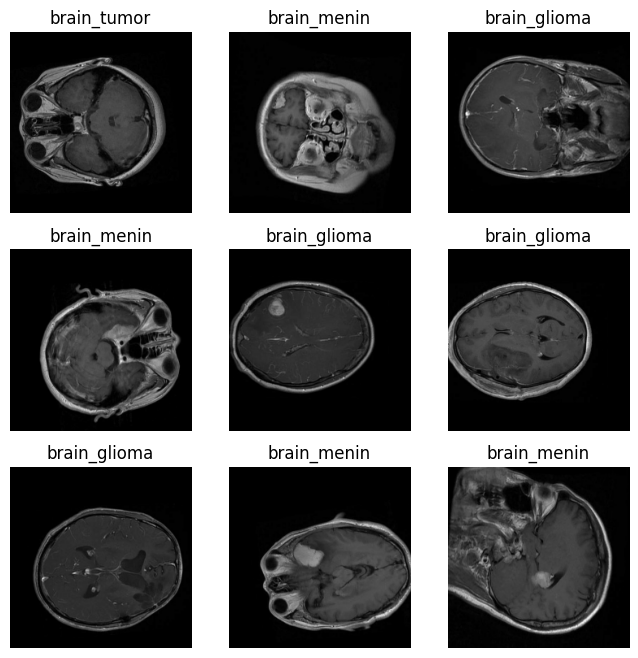

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        print(images[i].shape)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy().argmax()])
        plt.axis("off")

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

In [ ]:
# Creating training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 6056 files belonging to 3 classes.
Using 4845 files for training.
Found 6056 files belonging to 3 classes.
Using 1211 files for validation.


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

In [ ]:
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
# 1. Define the base model
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# 2. Build the full model using data augmentation
model = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

# 3. Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# Compile the ResNet model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
import tensorflow as tf
import kagglehub
import os

# 1. Resolve Dataset Path
path = kagglehub.dataset_download("orvile/brain-cancer-mri-dataset")
DATASET_PATH = os.path.join(path, 'Brain_Cancer raw MRI data', 'Brain_Cancer')
# Reduced image size for speed
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# 2. Load Data
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Optimize data loading performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# 3. Build Model (MobileNetV2 is much faster than ResNet50)
base_model = tf.keras.applications.MobileNetV2(weights="imagenet", include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(optimizer='adam', loss="categorical_crossentropy", metrics=["accuracy"])

# 4. Train (Reduced epochs for fast completion)
print("Starting fast training...")
history = model.fit(train_ds, validation_data=val_ds, epochs=3)

Using Colab cache for faster access to the 'brain-cancer-mri-dataset' dataset.
Found 6056 files belonging to 3 classes.
Using 4845 files for training.
Found 6056 files belonging to 3 classes.
Using 1211 files for validation.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Starting fast training...
Epoch 1/3
152/152 ━━━━━━━━━━━━━━━━━━━━ 97s 599ms/step - accuracy: 0.8384 - loss: 0.4258 - val_accuracy: 0.9083 - val_loss: 0.2790
Epoch 2/3
152/152 ━━━━━━━━━━━━━━━━━━━━ 86s 555ms/step - accuracy: 0.9115 - loss: 0.2383 - val_accuracy: 0.8951 - val_loss: 0.2560
Epoch 3/3
152/152 ━━━━━━━━━━━━━━━━━━━━ 87s 569ms/step - accuracy: 0.9247 - loss: 0.2023 - val_accuracy: 0.9290 - val_loss: 0.2014


In [ ]:
import numpy as np

y_true = []
y_pred = []
y_pred_prob = []

# Ensure val_ds is iterated to collect ground truth and predictions
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
    y_pred_prob.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_pred_prob = np.array(y_pred_prob)

print("Evaluation complete.")

In [2]:
import os

# Clone the repository
!git clone https://github.com/Abhishek2993/BrainCancer-Detection-MRI-DATA-.git

# List the contents of the cloned directory to confirm
print(os.listdir('BrainCancer-Detection-MRI-DATA-'))

Cloning into 'BrainCancer-Detection-MRI-DATA-'...
['.git']


### User Interface: Upload MRI and Get Recommendations
This section allows users to upload a scan, identify the cancer type, and automatically search for treatment information.

In [ ]:
from google.colab import files
import PIL.Image
import numpy as np

def get_recommendations(disease_type):
    # This is a placeholder for search logic
    # In a real scenario, you could use Serper or Google Search API
    query_cost = f"average cost of {disease_type} treatment by country 2024"
    query_doctors = f"best neuro-oncologists for {disease_type} globally"

    print(f"\n--- Search Queries for {disease_type} ---")
    print(f"1. Searching for: {query_cost}")
    print(f"2. Searching for: {query_doctors}")
    print("\n--- Estimated Insights (Simulated) ---")
    print("- Cheapest Treatment: Often found in India, Turkey, or Thailand (approx. $5,000 - $15,000).")
    print("- Best Centers: Mayo Clinic (USA), Charité (Germany), or Tata Memorial (India).")

def run_app():
    uploaded = files.upload()
    for fn in uploaded.keys():
        # Load and preprocess image
        img = PIL.Image.open(fn).resize((128, 128))
        img_array = tf.keras.utils.img_to_array(img)
        img_array = tf.expand_dims(img_array, 0) # Create a batch

        # Predict
        predictions = model.predict(img_array)
        score = tf.nn.softmax(predictions[0])
        predicted_class = class_names[np.argmax(score)]
        confidence = 100 * np.max(score)

        print(f"\nDetection Result: {predicted_class} ({confidence:.2f}% confidence)")

        # Fetch treatment info
        get_recommendations(predicted_class)

# Uncomment the line below to run the interface
# run_app()